# 05 · MSE anchors and freezing

This notebook is the **starting point of the research question**: can the soft staircase, helped by anchors that pull
each weight to its level and by freezing weights once they are decided, beat STE at very low bit widths?

| Step | What you will see |
|---|---|
| 1 | the anchor term and its gradient |
| 2 | the fused anchor: computed inside the layer's backward pass, and how much memory it saves |
| 3 | freezing: when is a weight "decided"? |
| 4 | an experiment at 2 bits on CIFAR: soft, soft + anchor, soft + anchor + freezing, and STE versions |
| 5 | how the distance to the level evolves during training |

**Tags** (see notebook 00): 📘 common practice · 📗 known, less common · 🧪 new or modified in vvtk_quant.

This notebook is mostly 🧪. Read first: ProxQuant (arXiv:1810.00861) and Nagel et al. 2022 (arXiv:2203.11086), the
two published ideas closest to the anchor and to freezing.

In [1]:
import os, sys, copy, math, time
sys.path.insert(0, os.path.abspath(".."))
import numpy as np
import torch, torch.nn as nn
import matplotlib.pyplot as plt
from vvtk_quant import VVTK_QModel, dquant_fast, quant
from vvtk_quant.quant import fused_quant, local_step
from common_cifar import DEVICE, loaders, evaluate, pretrained_fp32
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## Step 1 · The anchor

Training loss plus a pull of every latent weight towards its nearest level $Q(w)$. vvtk_quant has two forms:

$$A_{\text{soft}} = \frac1N\sum_j \big(Q_T(w_j) - Q(w_j)\big)^2, \qquad
  A_{\text{weight}} = \frac1N \sum_j \Big(\frac{w_j - Q(w_j)}{\Delta(w_j)}\Big)^2,$$

where $\Delta(w)$ is the local step. $A_{\text{soft}}$ (the v0.x one) measures the mismatch between the soft value used
in training and the deployed value; it vanishes when $T$ is large. $A_{\text{weight}}$ is scale-free (units of a step)
and works for STE as well. With Lloyd-Max levels, $Q(w)$ is the **centroid of the bin**: the anchor pulls weights to the
MSE-optimal points of notebook 02. The total objective is

$$\mathcal{L}_{\text{total}} = \mathcal{L}_{\text{task}}\big(Q_T(w)\big) + \lambda\, A .$$

Its gradient, per weight:

$$\frac{\partial A_{\text{soft}}}{\partial w} = \frac{2}{N}\,(Q_T - Q)\,Q_T'(w), \qquad
  \frac{\partial A_{\text{weight}}}{\partial w} = \frac{2}{N}\,\frac{w - Q(w)}{\Delta^2} .$$

$A_{\text{weight}}$ is a spring towards the level; $A_{\text{soft}}$ acts only where $Q_T'$ is large, i.e. near the limits.

> 📗 **Known, less common:** regularizers/prox steps that pull weights towards the quantization grid (ProxQuant,
> arXiv:1810.00861). 🧪 **vvtk_quant:** $A_{\text{soft}}$ (the mismatch between soft and hard values) and
> $A_{\text{weight}}$ measured in units of the local step of a non-uniform grid, combined with the soft staircase.

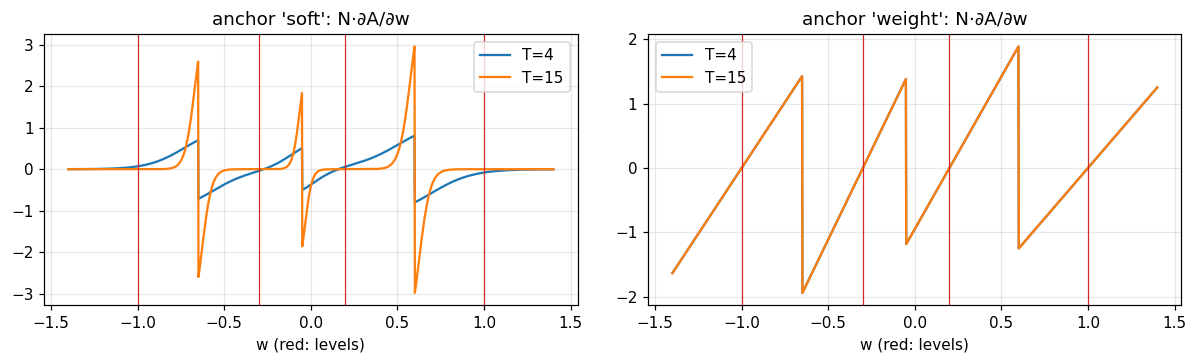

In [2]:
levels = torch.tensor([-1.0, -0.3, 0.2, 1.0])
x = torch.linspace(-1.4, 1.4, 1500)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for anchor in ["soft", "weight"]:
    for T in [4.0, 15.0]:
        xg = x.clone().requires_grad_(True)
        fused_quant(xg, levels, temp=T, anchor=anchor, lam=1.0).sum().backward()    # task + anchor gradient
        xg2 = x.clone().requires_grad_(True)
        fused_quant(xg2, levels, temp=T, anchor=anchor, lam=0.0).sum().backward()   # task gradient only
        ax[0 if anchor == "soft" else 1].plot(x, (xg.grad - xg2.grad) * x.numel(), label=f"T={T:g}")
for a, t in zip(ax, ["anchor 'soft': N·∂A/∂w", "anchor 'weight': N·∂A/∂w"]):
    for l in levels: a.axvline(l, color="C3", lw=0.8)
    a.set_title(t); a.legend(); a.set_xlabel("w (red: levels)")
plt.tight_layout(); plt.show()

Gradient descent moves $w$ against these curves: towards the red levels in both cases.

## Step 2 · The fused anchor: inside the layer, on the backward pass

The simple way to add $\lambda A$ is to compute it in the forward pass and add it to the loss. Autograd then keeps, for
**every** quantized layer, all the intermediate tensors of the soft staircase (indices, neighbour levels, two sigmoids,
the anchor's own graph) alive from the forward to the backward pass: several copies of each weight matrix.

`FusedQuant` (`vvtk_quant/quant.py`) saves only $w$ and the levels. In the backward pass it recomputes the staircase and
returns directly

$$\frac{\partial \mathcal{L}_{\text{total}}}{\partial w} = g \odot Q_T'(w) + \lambda\, \frac{\partial A}{\partial w},$$

with $g$ the gradient coming from the layer's output. The value of $A$ is still reported (`qmodel.qloss`) for logging,
without a graph. It is the default (`fused=True`, `anchor_lambda=λ`). Same gradients, much less memory:

> 🧪 **vvtk_quant (implementation).** Recomputing in the backward pass instead of storing is standard (gradient
> checkpointing); doing it for the quantizer and adding the regularizer gradient analytically inside the same custom
> `autograd.Function` is our implementation. It is an engineering contribution: the measured memory is the evidence.

In [3]:
def held_memory(fused, layers=8, d=2048):
    torch.manual_seed(0)
    net = nn.Sequential(*[nn.Linear(d, d) for _ in range(layers)]).to(DEVICE)
    q = VVTK_QModel(net, b=4, module_types=[nn.Linear], fused=fused, anchor_lambda=0.1 if fused else 0.0)
    q.calibrate_quant(method="eqprob"); q.update_temp(4.0); q.train()
    x = torch.randn(8, d, device=DEVICE)
    torch.cuda.synchronize(); base = torch.cuda.memory_allocated(); torch.cuda.reset_peak_memory_stats()
    loss = q(x).pow(2).mean()
    if not fused:
        loss = loss + 0.1 * q.qloss
    held = torch.cuda.memory_allocated() - base
    t = time.time(); loss.backward(); torch.cuda.synchronize(); tb = time.time() - t
    peak = torch.cuda.max_memory_allocated() - base
    grads = torch.cat([m.weight.grad.flatten() for m in q.qmodules()])
    return held / 2**20, peak / 2**20, tb * 1000, grads

if DEVICE.type == "cuda":
    wmb = 8 * 2048 * 2048 * 4 / 2**20
    a = held_memory(False); b = held_memory(True)
    print(f"8 layers of 2048x2048 (weights: {wmb:.0f} MB)")
    print(f"{'':<22} | {'held fwd->bwd (MB)':>18} | {'peak (MB)':>9} | {'backward (ms)':>13}")
    print(f"{'autograd anchor':<22} | {a[0]:18.0f} | {a[1]:9.0f} | {a[2]:13.1f}")
    print(f"{'fused anchor':<22} | {b[0]:18.0f} | {b[1]:9.0f} | {b[2]:13.1f}")
    print("max |grad difference|:", (a[3] - b[3]).abs().max().item())
else:
    print("needs a GPU to measure memory")

8 layers of 2048x2048 (weights: 128 MB)
                       | held fwd->bwd (MB) | peak (MB) | backward (ms)
autograd anchor        |               1018 |      1210 |          45.8
fused anchor           |                113 |       456 |          24.7
max |grad difference|: 4.547473508864641e-13


The memory held between forward and backward grows with the **number of layers** (it is what limits the model size
you can train); the fused version keeps it close to the activations alone. The remaining peak is one layer's
recomputation, transient.

## Step 3 · Freezing

A weight is **decided** when its latent value sits well inside a bin: $d(w) = |w - Q(w)|/\Delta(w)$ is small
($d=0$ on the level, $d=0.5$ on a limit). `qmodel.freeze(eps)` fixes every weight with $d < \varepsilon$ to its level for
the rest of training: its gradient is zero from then on. Benefits:
* no more oscillation for that weight (Nagel et al. 2022 freeze weights that oscillate; here we freeze those that
  are *stable*);
* a frozen weight needs no optimizer state and no float master copy: the memory saving grows as training proceeds
  (not implemented yet in the optimizer: an exercise).

The anchor and freezing work together: the anchor drives weights towards $d=0$, freezing locks them.

> 📗 **Known, less common:** iterative freezing of **oscillating** weights (Nagel et al. 2022, arXiv:2203.11086).
> 🧪 **vvtk_quant:** freezing the **stable** weights (by distance to the level), with the aim of dropping their optimizer
> state and master copy (training memory), and combining it with the anchor.

## Step 4 · Experiment: 2 bits on CIFAR

Same fair budget as notebook 04 (3 epochs from the 5-epoch float checkpoint, Adam $3\cdot10^{-4}$, cosine, $T: 2\to40$).
The anchor weight ramps linearly from 0 to $\lambda_{\max}$, because a strong anchor at the start decides weights
before the network has adapted (we saw it in notebook 01, Step 7). Freezing starts after the first epoch:
every 100 steps, freeze weights with $d < 0.05$.

> 🧪 The ramp schedule of $\lambda$ and the freezing schedule are our choices (hyperparameters to study), not
> established recipes.

In [4]:
train_loader, test_loader = loaders()
fp32 = pretrained_fp32(train_loader, test_loader, epochs=5)
EPOCHS, LR, T0, T1, B = 3, 3e-4, 2.0, 40.0, 2
spe = len(train_loader); total = EPOCHS * spe
VARIANTS = {
    "ste":                      dict(mode="ste", lam=0.0, freeze=False),
    "ste+anchor+freeze":        dict(mode="ste", lam=1.0, freeze=True),
    "soft":                     dict(mode="soft", lam=0.0, freeze=False),
    "soft+anchor":              dict(mode="soft", lam=1.0, freeze=False),
    "soft+anchor+freeze":       dict(mode="soft", lam=1.0, freeze=True),
}

def run(name, seed=0):
    v = VARIANTS[name]
    torch.manual_seed(seed)
    q = VVTK_QModel(copy.deepcopy(fp32), b=B, module_types=[nn.Conv2d, nn.Linear], mode=v["mode"], temp=T0,
                    anchor="weight", anchor_lambda=0.0)
    q.calibrate_quant(method="lloyd")
    opt = torch.optim.Adam(q.parameters(), LR)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda t: 0.5 * (1 + math.cos(math.pi * t / total)))
    crit = nn.CrossEntropyLoss()
    log = {"acc": [evaluate(q, test_loader)], "frozen": [], "dist": [q.distance_to_level().cpu().numpy()]}
    step = 0
    for ep in range(EPOCHS):
        q.train()
        for xb, yb in train_loader:
            frac = step / (total - 1)
            if v["mode"] == "soft":
                q.update_temp(T0 * (T1 / T0) ** frac)
            q.set_anchor(v["lam"] * frac)                  # linear ramp 0 -> lambda_max
            if v["freeze"] and step >= spe and step % 100 == 0:
                q.freeze(eps=0.05)
            xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
            loss = crit(q(xb), yb)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sched.step()
            if step % 50 == 0:
                log["frozen"].append((step, q.frozen_fraction()))
            step += 1
        log["acc"].append(evaluate(q, test_loader))
        log["dist"].append(q.distance_to_level().cpu().numpy())
        print(f"  {name:<20} epoch {ep + 1}: hard test acc {log['acc'][-1]:5.2f}%   frozen {100 * q.frozen_fraction():5.1f}%")
    return log

L = {name: run(name) for name in VARIANTS}

loaded /tmp/claude-5043/-extra3-cadrete-work-src-research-manager/a0d434e7-6c88-467d-a255-71a045eaa3fa/scratchpad/vvtk_quant_src/vvtk_quant/examples/out/cifar_fp32_e5_s0.pth


  ste                  epoch 1: hard test acc 77.46%   frozen   0.0%


  ste                  epoch 2: hard test acc 78.12%   frozen   0.0%


  ste                  epoch 3: hard test acc 80.39%   frozen   0.0%


  ste+anchor+freeze    epoch 1: hard test acc 77.41%   frozen   0.0%


  ste+anchor+freeze    epoch 2: hard test acc 79.04%   frozen  33.5%


... (6 outputs left out)

  soft+anchor          epoch 3: hard test acc 74.17%   frozen   0.0%


  soft+anchor+freeze   epoch 1: hard test acc 64.51%   frozen   0.0%


  soft+anchor+freeze   epoch 2: hard test acc 70.81%   frozen  41.8%


  soft+anchor+freeze   epoch 3: hard test acc 75.78%   frozen  52.8%


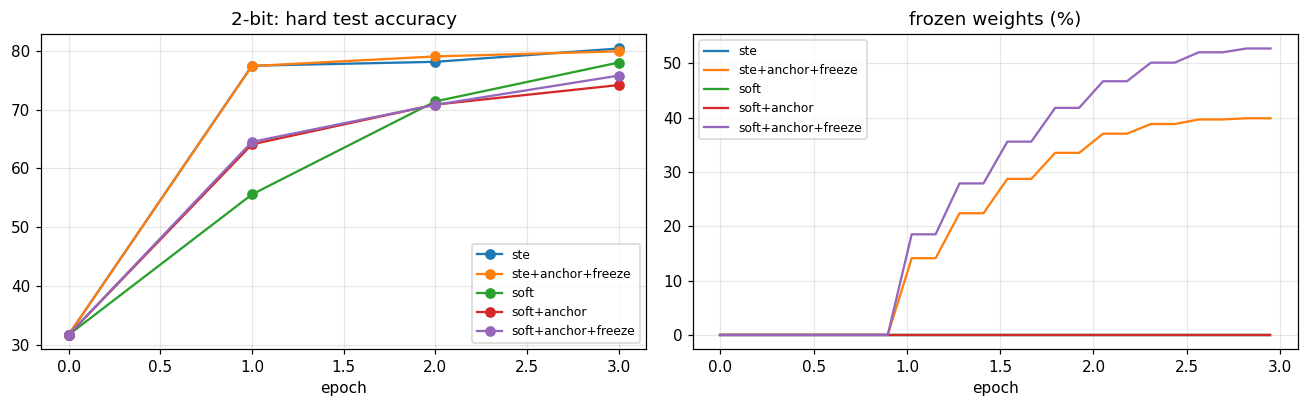

variant                |    PTQ | after QAT | frozen
ste                    |  31.68 |     80.39 |   0.0%
ste+anchor+freeze      |  31.68 |     79.91 |  39.9%
soft                   |  31.68 |     78.00 |   0.0%
soft+anchor            |  31.68 |     74.17 |   0.0%
soft+anchor+freeze     |  31.68 |     75.78 |  52.8%


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for name, lg in L.items():
    ax[0].plot(range(EPOCHS + 1), lg["acc"], "o-", label=name)
    f = np.array(lg["frozen"]); ax[1].plot(f[:, 0] / spe, 100 * f[:, 1], label=name)
ax[0].set_title(f"{B}-bit: hard test accuracy"); ax[0].set_xlabel("epoch"); ax[0].legend(fontsize=8)
ax[1].set_title("frozen weights (%)"); ax[1].set_xlabel("epoch"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"{'variant':<22} | {'PTQ':>6} | {'after QAT':>9} | {'frozen':>6}")
for name, lg in L.items():
    print(f"{name:<22} | {lg['acc'][0]:6.2f} | {lg['acc'][-1]:9.2f} | {100 * lg['frozen'][-1][1]:5.1f}%")

## Step 5 · How decided are the weights?

Distribution of $d(w)$ at the start and at the end of every epoch. The anchor should move mass towards $d=0$;
without it, weights spread over the whole bin.

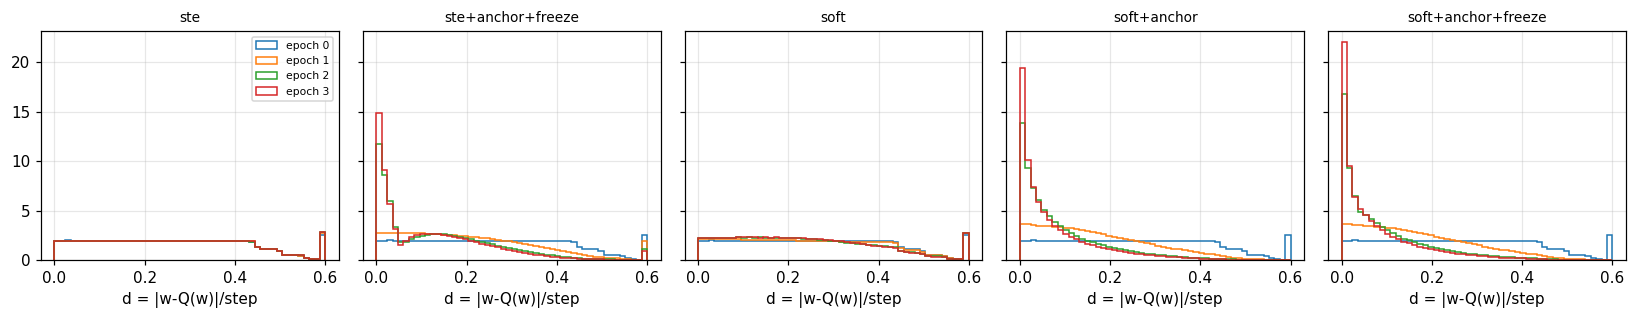

In [6]:
fig, axs = plt.subplots(1, len(L), figsize=(15, 3.0), sharey=True)
for ax, (name, lg) in zip(axs, L.items()):
    for ep, dist in enumerate(lg["dist"]):
        ax.hist(np.clip(dist, 0, 0.6), bins=50, histtype="step", density=True, label=f"epoch {ep}")
    ax.set_title(name, fontsize=9); ax.set_xlabel("d = |w-Q(w)|/step")
axs[0].legend(fontsize=7); plt.tight_layout(); plt.show()

### What this v1.0 run shows (one seed; numbers in the cells above)

* **Fused anchor, Step 2:** memory held between forward and backward 1018 MB → 113 MB, backward 46 → 25 ms, same
  gradients (max difference ~1e-13). This part is an engineering result and it holds.
* **2-bit CIFAR:** STE 80.4 %; STE + anchor + freezing 79.9 % **with 40 % of the weights frozen** for the last two
  epochs. Freezing cost about half a point here, which is what makes the memory idea worth testing (a frozen weight
  needs no Adam state).
* The soft variants stay behind STE (78.0 %, 74.2 % with anchor, 75.8 % with anchor + freezing, 53 % frozen). With
  the soft staircase, freezing *helped* the anchor version (+1.6 points), a hint that the anchor ramp is too strong or
  too early when weights cannot settle.
* Treat all of this as a starting point: one seed, an under-trained float model, untuned $\lambda$, $T$ and $\varepsilon$.

### Open questions for the study
1. **Schedules.** When should the anchor start, how fast should it grow, and should $T$ and $\lambda$ be coupled
   (e.g. $\lambda \propto 1/T$)?
2. **Freezing rule.** Distance threshold, stability over a window (no flip in the last $k$ checks), or Nagel's
   oscillation counter? Freeze in order of confidence until a target fraction?
3. **Memory.** Make the optimizer drop the Adam state of frozen weights and measure the training memory as a function
   of the frozen fraction. This connects with master-weight-free training.
4. **Levels during training.** Should the levels themselves move (re-run Lloyd every epoch on the latent weights, or
   learn them by gradient)? Frozen weights would then need to follow their level.
5. **Fair STE baselines.** STE + LSQ, STE + anchor + freeze (above), and the oscillation dampening of Nagel et al.
6. **From scalar to vector levels.** Lloyd-Max is 1-D k-means; vector quantization (📗, e.g. AQLM, arXiv:2401.06118)
   quantizes groups of $d$ weights to codewords in $\mathbb{R}^d$. At 2 bits/weight, $d=2$ with 16 codewords keeps
   the bit budget and can follow correlations. The anchor and freezing carry over: "nearest level" becomes "nearest
   codeword". 🧪 Soft assignment to codewords with an annealed temperature is the VQ version of the soft staircase.

Each question is a small experiment on the tiny LM (06) or the phoneme decoder (07) first, then on a larger model.

**Next:** [06 · A tiny language model](06_tiny_lm.ipynb).